in this notebook, we combine three diagnostic measures (studentized residuals, leverage, and cook's distance) on a single scatter plot to spot problematic observations.

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# import the csv into dataframe
data1 = pd.read_csv("../../data/Données SPY.csv")
data2 = pd.read_csv("../../data/AAPL.csv")
data3 = pd.read_csv("../../data/USD_CNY.csv")
data4 = pd.read_csv("../../data/DTB6.csv")
data5 = pd.read_csv("../../data/HIS.csv")
data6 = pd.read_csv("../../data/Gold.csv")
data7 = pd.read_csv("../../data/TCD6.csv")
data8 = pd.read_csv("../../data/DR5.xls")
data9 = pd.read_csv("../../data/Taux_ST6.xls")
data10 = pd.read_csv("../../data/VRV.xls")

# standardize columns and convert date
for df in [data1, data2, data3, data4, data5, data6, data7, data8, data9, data10]:
    df.columns = [col.strip().capitalize() for col in df.columns]
    if 'Unnamed: 0' in df.columns:
        df.rename(columns={'Unnamed: 0':'Date'}, inplace=True)
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# compute returns before merging
# specific cleaning for the his file
data5['Price'] = data5['Price'].astype(str)
data5['Price'] = data5['Price'].str.replace(',', '', regex=False)  # remove commas
data5['Price'] = pd.to_numeric(data5['Price'], errors='coerce')

col_names = ['SPY','AAPL','DollarYuan','DTB6','HIS','Or','DCD6M', 'DR5', 'Taux_ST6', 'VRV']
col_prices = ['Price','Price','Price','Dtb6','Price','Price','Dcd6m','Price', 'Price', 'Price']
dataframes = [data1, data2, data3, data4, data5, data6, data7, data8, data9, data10]

for df, name, price in zip(dataframes, col_names, col_prices):
    if price in df.columns:
        # convert column to numeric before calculation
        df[price] = pd.to_numeric(df[price], errors='coerce')
        # compute daily return in proportion
        df[name] = df[price].pct_change()
        # drop first nan rows
        df.dropna(subset=[name], inplace=True)

# merge files on date column with outer join
# start from spy already converted to return
data_merged = data1[['Date','SPY']]

# list of remaining files to merge
dfs = [data2, data3, data4, data5, data6, data7, data8, data9, data10]
col_names = ['AAPL','DollarYuan','DTB6','HIS','Or','DCD6M','DR5', 'Taux_ST6', 'VRV' ]
col_prices = ['AAPL','DollarYuan','DTB6','Price','Or','DCD6M','Dr5', 'St6', 'Vrv']  # merge on already computed returns

for df, col_name, price_col in zip(dfs, col_names, col_prices):
    data_merged = data_merged.merge(df[['Date', price_col]], on='Date', how='outer')
    data_merged.rename(columns={price_col: col_name}, inplace=True)

# fill missing values
data_merged.ffill(inplace=True)
data_merged.bfill(inplace=True)
for col in ['SPY','AAPL','DollarYuan','DTB6','HIS','Or','DCD6M','DR5', 'Taux_ST6', 'VRV' ]:
    data_merged[col] = pd.to_numeric(data_merged[col], errors='coerce')
    if data_merged[col].isna().sum() > 0:
        data_merged[col] = data_merged[col].fillna(data_merged[col].mean())

# drop columns with more than 50% nan
X_multi = data_merged[['AAPL','DollarYuan','DTB6','HIS','Or','DCD6M','DR5', 'Taux_ST6', 'VRV']]
X_multi = X_multi.loc[:, X_multi.isna().mean() < 0.5]
y = data_merged[['SPY']]

# final cleaning: drop remaining rows with nan
data_clean = pd.concat([X_multi, y], axis=1).dropna()
X_multi = data_clean.drop(columns=['SPY'])
y = data_clean[['SPY']]

# fit multiple ols regression model
X_multi_sm = sm.add_constant(X_multi)
mon_modele = sm.OLS(y, X_multi_sm).fit()

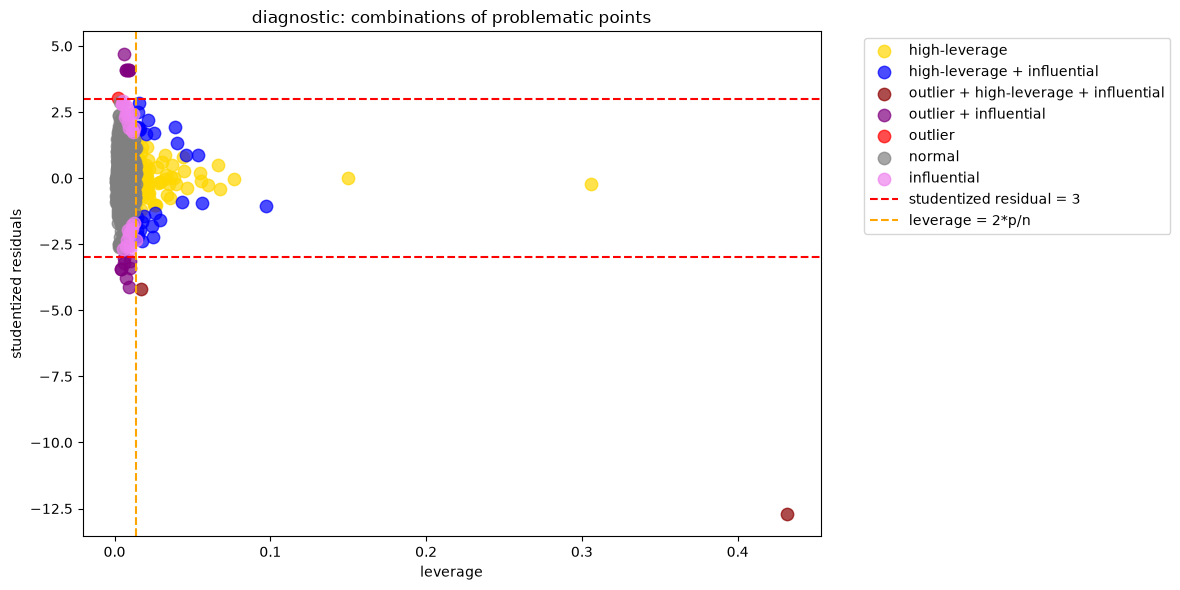

In [2]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
import numpy as np

influence = mon_modele.get_influence()
summary_frame = influence.summary_frame()

# diagnostic measures
resid_student = influence.resid_studentized_external
leverage = summary_frame['hat_diag']
cooks_d = summary_frame['cooks_d']

# thresholds
n, p = X_multi.shape
outlier_threshold = 3
leverage_threshold = 2 * p / n
cooks_threshold = 4 / n

# detect categories
is_outlier = abs(resid_student) > outlier_threshold
is_high_lev = leverage > leverage_threshold
is_influential = cooks_d > cooks_threshold

# assign colors according to combinations
colors = []
labels = []

for o, h, i in zip(is_outlier, is_high_lev, is_influential):
    if o and h and i:
        colors.append('darkred')
        labels.append('outlier + high-leverage + influential')
    elif o and h:
        colors.append('orange')
        labels.append('outlier + high-leverage')
    elif o and i:
        colors.append('purple')
        labels.append('outlier + influential')
    elif h and i:
        colors.append('blue')
        labels.append('high-leverage + influential')
    elif o:
        colors.append('red')
        labels.append('outlier')
    elif h:
        colors.append('gold')
        labels.append('high-leverage')
    elif i:
        colors.append('violet')
        labels.append('influential')
    else:
        colors.append('gray')
        labels.append('normal')

# plot
plt.figure(figsize=(12,6))
for c, lbl in set(zip(colors, labels)):
    idx = [j for j, l in enumerate(labels) if l == lbl]
    plt.scatter(leverage[idx], resid_student[idx], c=c, s=80, alpha=0.7, label=lbl)

plt.axhline(y=outlier_threshold, color='red', linestyle='--', label='studentized residual = 3')
plt.axhline(y=-outlier_threshold, color='red', linestyle='--')
plt.axvline(x=leverage_threshold, color='orange', linestyle='--', label='leverage = 2*p/n')
plt.xlabel("leverage")
plt.ylabel("studentized residuals")
plt.title("diagnostic: combinations of problematic points")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

most of the points are gray (normal). we have a few points with high leverage or large residuals, and only a couple of extreme observations combining all criteria, so the regression is not overly distorted by a single anomaly.